# E4.02.2 — Fine-tuned Whisper encoder + SVM, with optional acoustic fusion

**Question:** Does the encoder from the fine-tuned transcription model improve accent classification over frozen Whisper features?

Use **Run All** with the **Singlish final fusion (Python 3.14)** kernel. Save this notebook before the run. This notebook has no experiment results yet.

The transcription model is `whisper-small-mnsc-sg-15k-heldout`. It was fine-tuned for ASR before this test. Here, its weights stay fixed. Extract encoder features, then train an SVM for the Singapore/non-Singapore label. Do not generate transcripts. This test measures classification, not word error rate.

| Model | Encoder | SVM inputs | Purpose |
|---|---|---:|---|
| Frozen small SVM768 | Pretrained multilingual Whisper-small | 768 | Matched control for encoder fine-tuning |
| Fine-tuned small SVM768 | Fine-tuned transcription Whisper-small | 768 | Main candidate |
| Frozen base.en SVM512 | Completed E2 model | 512 | Compare with the strongest existing frozen control |
| Frozen base.en PCA32 SVM | Completed E2 model | 32 | Supporting project reference |
| Optional small fusion, one per small encoder | Same small encoders + acoustic65 | 65 + PCA32 | Compare matched acoustic fusion models |

**Primary comparison:** fine-tuned small SVM768 minus frozen small SVM768. Both use the same architecture, audio, pooling, SVM pipeline, and C search. **Secondary comparison:** fine-tuned small SVM768 minus frozen base.en SVM512. This second comparison also changes model size and language training. It does not isolate fine-tuning.

The optional fusion test is off by default. The main SVM test can run while A1 is still running. Enable fusion only after A1 has saved its training-only acoustic ranking. No acoustic ranking is repeated here.

In [1]:
from pathlib import Path
from time import perf_counter
from datetime import datetime, timezone
from importlib.metadata import version
import hashlib
import importlib.util
import json
import platform
import tempfile

import joblib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

ROOT = Path('/home/mh/nusproj/singlish-whisper')
NOTEBOOK = ROOT / 'notebooks/E4_02_2_finetuned_whisper_svm_and_fusion.ipynb'
DATA = ROOT / 'data/accent_dataset_3to6s_40k'
UPSTREAM = Path('/home/mh/nusproj/E1_Feature_EngineeringV4/outputs')
E1 = UPSTREAM / 'e1_feature_study_accent_40000'
E4 = UPSTREAM / 'svm65_fusion_comparison_40000'
E2 = ROOT / 'outputs/frozen_whisper_40000_20261028'
# A separate folder preserves the historical E1, E2, and E4 results.
OUT = ROOT / 'outputs/e4_02_2_finetuned_whisper_svm_40000'

SEED = 42
C_VALUES = [0.01, 0.1, 1.0, 10.0]
FEATURE_COUNT = 65
PCA_WIDTH = 32
PERMUTATION_REPEATS = 5
BOOTSTRAP_REPEATS = 2000
ACOUSTIC = 'Acoustic SVM65'
FUSION = 'Fusion SVM65+32'
WHISPER = ['Whisper full512 SVM', 'Whisper PCA32 SVM']
NAMES = [ACOUSTIC, *WHISPER, FUSION]
NEW_MODELS = [ACOUSTIC, FUSION]
PACKAGES = {name: version(name) for name in
            ['numpy', 'pandas', 'scipy', 'scikit-learn', 'joblib',
             'matplotlib', 'pyarrow', 'soundfile']}

def sha256(path):
    result = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            result.update(block)
    return result.hexdigest()

HELPER = ROOT / 'notebooks/frozen_whisper_40k.py'
assert sha256(HELPER) == '2575187bf0e0e1c8cc1b0f285f2eba91ccefa8b329d7ac1f49d33c65e7b62d70', \
    'The completed E2 helper changed. Check the input provenance before continuing.'
spec = importlib.util.spec_from_file_location('a1_verified_e2_helper', HELPER)
fw = importlib.util.module_from_spec(spec)
spec.loader.exec_module(fw)

EXPECTED_E2_HASHES = {
    'run_metadata.json': '7cc0f7114c70786fdbc0b194c68af65c5572df7d5933b4d2a910b0f8f35c3a2a',
    'test_predictions.csv': '1aff74b323c42cc0439104911a8d929a11429d9f1af527827feb10311c87efc2',
    'validation_predictions.csv': '946277045484bb601a5b07cc4d7fb679393124246a6a5812521da9d77e4dcdf1',
    'validation_C_trials.csv': '6a694009f5da318c85943f94a8779f6498e123c3364ef01d7c6eda1f55dd785a',
    'selected_C.json': 'ced56dac7fd994361a282305fe93c165575985bd4bc9a8ea81939ce541e5a004',
    'timing.csv': 'cdaedcb063585c892e5834ccf17b1b99c44530b099fb26e8548fccdee6ccdbdb',
    'test_metrics.json': 'a074dd89a695164de2b112f43bc1a873ec19d34f7b980f4a2397f3777eda97eb',
    'whisper_full512_svm.joblib': '6e05966265094626349ed6ec2267bf515e333da4fc47d3b539e8f38fa8be4d08',
    'whisper_pca32_svm.joblib': 'e6cd74aabcd6162d40f011b20d2cdc7717c7f375f931d32bffa34175b0e2611b',
}


import gc
import io
import torch
import pyarrow.parquet as pq
import soundfile as sf
from safetensors import safe_open
from transformers import WhisperConfig, WhisperFeatureExtractor
from transformers.models.whisper.modeling_whisper import WhisperEncoder

FINE_TUNED = Path('/home/mh/nusproj/Singlish/mvp/models/whisper-small-mnsc-sg-15k-heldout')
SMALL_REVISION = '973afd24965f72e36ca33b3055d56a652f456b4d'
PRETRAINED = Path.home() / '.cache/huggingface/hub/models--openai--whisper-small/snapshots' / SMALL_REVISION
A1 = ROOT / 'outputs/a1_tuned_acoustic_whisper_fusion_40000'
INCLUDE_FUSION = False  # Optional. Set before the first run; use a new OUT for changed settings.
BATCH_SIZE = 8          # GPU: lower to 4 or 2 if memory is insufficient. CPU uses at most 2.
# Optional CSV of all audio exposed during ASR training AND checkpoint selection.
# See section 3. Missing records do not stop extraction; they limit the conclusion.
ASR_EXPOSURE_CSV = None  # Example: Path('/absolute/path/asr_exposure.csv')

FROZEN_SMALL = 'Frozen small SVM768'
TUNED_SMALL = 'Fine-tuned small SVM768'
FROZEN_FUSION = 'Frozen small fusion65+32'
TUNED_FUSION = 'Fine-tuned small fusion65+32'
NEW_MODELS = [FROZEN_SMALL, TUNED_SMALL]
if INCLUDE_FUSION:
    NEW_MODELS += [FROZEN_FUSION, TUNED_FUSION]
NAMES = [*WHISPER, *NEW_MODELS]
COMPARISONS = [(TUNED_SMALL, FROZEN_SMALL), (TUNED_SMALL, WHISPER[0])]
if INCLUDE_FUSION:
    COMPARISONS += [(TUNED_FUSION, FROZEN_FUSION), (TUNED_FUSION, TUNED_SMALL),
                    (TUNED_FUSION, WHISPER[0])]
PACKAGES.update({name: version(name) for name in ['torch', 'transformers', 'safetensors']})
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '| encoder batch size:', BATCH_SIZE if DEVICE.type == 'cuda' else min(BATCH_SIZE, 2))
print('Optional fusion:', INCLUDE_FUSION, '| output:', OUT)
print('No transcription decoding and no new Whisper fine-tuning.')

/home/mh/miniconda3/envs/singlish-py314/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda | encoder batch size: 8
Optional fusion: False | output: /home/mh/nusproj/singlish-whisper/outputs/e4_02_2_finetuned_whisper_svm_40000
No transcription decoding and no new Whisper fine-tuning.


## 1. Keep selection and testing separate

1. Verify the final 24 October dataset and the completed E2 controls. Decode and check all audio hashes.
2. Check encoder weights and input settings. Extract each small encoder once. Average only real audio frames; exclude the 30-second padding from the average. Use the same prepared classification waveforms for all models.
3. For each new classifier, fit standard scaling and RBF SVM on **27,797 training clips**. Try C = 0.01, 0.1, 1, 10. Select C with **6,084 validation clips**. Break ties by macro F1, then smaller C.
4. Refit the chosen pipeline on **33,881 development clips**. Use **6,119 test clips** only after selection. Keep clip and speaker assignments unchanged.
5. Compare fixed predictions with 2,000 paired whole-speaker bootstrap samples. Report balanced accuracy, macro F1, ROC AUC, FP, FN, source scores, and time.

The test set has been inspected in earlier work. This is a retrospective comparison. All Singapore positives come from MNSC. Source and class are confounded. ASR exposure can add another source of leakage. A gain on this test alone does not prove broad accent generalization.

```text
Same prepared audio ─┬─ pretrained small encoder ─ mean768 ─ scaler + SVM ─┐
                     └─ fine-tuned small encoder ─ mean768 ─ scaler + SVM ─┤ compare
Completed E2 base.en predictions ──────────────────────────────────────────┘
Train: fit pipelines → Validation: select C → Development: refit → Test: compare
```

In [2]:
def make_model(name, c):
    classifier = SVC(C=float(c), kernel='rbf', gamma='scale', class_weight='balanced',
                     random_state=SEED, cache_size=2048)
    if name in [FROZEN_SMALL, TUNED_SMALL]:
        return Pipeline([('scale', StandardScaler()), ('classifier', classifier)])
    assert name in [FROZEN_FUSION, TUNED_FUSION]
    branch = Pipeline([('scale', StandardScaler()),
                       ('pca', PCA(n_components=32, random_state=SEED)),
                       ('component_scale', StandardScaler())])
    pre = ColumnTransformer([
        ('acoustic', StandardScaler(), list(range(65))),
        ('whisper', branch, list(range(65, 65+768)))],
        transformer_weights={'acoustic': 1/np.sqrt(65), 'whisper': 1/np.sqrt(32)})
    return Pipeline([('preprocess', pre), ('classifier', classifier)])


def check_fit_scope(model, name, values):
    if name in [FROZEN_SMALL, TUNED_SMALL]:
        assert model['scale'].n_samples_seen_ == len(values)
        np.testing.assert_allclose(model['scale'].mean_, values.mean(0, dtype=np.float64), atol=1e-9)
    else:
        pre = model['preprocess']
        for scaler, raw in [(pre.named_transformers_['acoustic'], values[:, :65]),
                            (pre.named_transformers_['whisper']['scale'], values[:, 65:])]:
            assert scaler.n_samples_seen_ == len(values)
            np.testing.assert_allclose(scaler.mean_, raw.mean(0, dtype=np.float64), atol=1e-9)
        assert pre.named_transformers_['whisper']['pca'].n_samples_ == len(values)
        assert pre.named_transformers_['whisper']['component_scale'].n_samples_seen_ == len(values)
        assert pre.transform(values[:2]).shape == (2, 97)


PRED_COLUMNS = ['clip_id', 'speaker_group', 'source', 'accent_group', 'label',
                'model', 'stage', 'prediction', 'decision_score']


def check_predictions(predictions, expected, name, stage):
    assert len(predictions) == len(expected) and predictions.clip_id.is_unique
    part = predictions.set_index('clip_id').sort_index()
    truth = expected.set_index('clip_id').sort_index()
    pd.testing.assert_frame_equal(part[['speaker_group', 'source', 'accent_group', 'label']],
                                  truth[['speaker_group', 'source', 'accent_group', 'label']],
                                  check_dtype=False)
    assert predictions.model.eq(name).all() and predictions.stage.eq(stage).all()
    assert set(predictions.prediction) <= {0, 1}
    assert np.isfinite(predictions.decision_score).all()


def score_predictions(model, values, expected, name, stage):
    part = expected[['clip_id', 'speaker_group', 'source', 'accent_group', 'label']].copy()
    part['model'], part['stage'] = name, stage
    part['prediction'] = model.predict(values)
    part['decision_score'] = model.decision_function(values)
    part = part[PRED_COLUMNS].reset_index(drop=True)
    check_predictions(part, expected, name, stage)
    return part


def choose_trial(trials):
    return max(trials, key=lambda row: (row['balanced_accuracy'], row['macro_f1'], -row['C']))


def save_checkpoint(state):
    temporary = OUT / 'study.joblib.tmp'
    joblib.dump(state, temporary, compress=3)
    temporary.replace(OUT / 'study.joblib')


def paired_bootstrap(predictions, names, repeats=BOOTSTRAP_REPEATS, seed=SEED):
    # Aggregate confusion counts by speaker. Reuse each draw across all models.
    parts = {name: predictions.loc[predictions.model.eq(name)].set_index('clip_id').sort_index()
             for name in names}
    reference = parts[names[0]][['speaker_group', 'label']]
    assert reference.index.is_unique
    assert reference.groupby('speaker_group').label.nunique().eq(1).all()
    for part in parts.values():
        pd.testing.assert_frame_equal(part[['speaker_group', 'label']], reference)
    speakers = reference.groupby('speaker_group').label.first().sort_index()
    group_positions = speakers.index.get_indexer(reference.speaker_group)
    rng = np.random.default_rng(seed)
    weights = np.zeros((repeats, len(speakers)), dtype=np.int32)
    for label in [0, 1]:
        ids = np.flatnonzero(speakers.eq(label))
        assert len(ids) > 1, 'Each class needs at least two speakers.'
        draws = ids[rng.integers(len(ids), size=(repeats, len(ids)))]
        np.add.at(weights, (np.arange(repeats)[:, None], draws), 1)

    def from_cm(cm):
        tn, fp, fn, tp = np.asarray(cm).T
        return {'balanced_accuracy': .5*(tp/(tp+fn) + tn/(tn+fp)),
                'macro_f1': .5*(2*tp/(2*tp+fp+fn) + 2*tn/(2*tn+fp+fn))}

    samples, scores, rows = {}, {}, []
    for name, part in parts.items():
        cm = np.zeros((len(speakers), 4), dtype=np.int64)
        np.add.at(cm, (group_positions, 2*part.label.to_numpy()+part.prediction.to_numpy()), 1)
        samples[name] = from_cm(weights @ cm)
        result = fw.metrics(part)
        result['speaker_ci95'] = {metric: np.quantile(draws, [.025, .975]).tolist()
                                   for metric, draws in samples[name].items()}
        scores[name] = result
        rows.append(dict(model=name, **{k: v for k, v in result.items()
                                       if k not in ['confusion_matrix', 'speaker_ci95']},
                         ba_ci95_low=result['speaker_ci95']['balanced_accuracy'][0],
                         ba_ci95_high=result['speaker_ci95']['balanced_accuracy'][1],
                         f1_ci95_low=result['speaker_ci95']['macro_f1'][0],
                         f1_ci95_high=result['speaker_ci95']['macro_f1'][1]))
    comparisons = []
    for candidate_name, control in COMPARISONS:
        candidate = parts[candidate_name]
        correct_c = candidate.prediction.eq(candidate.label)
        correct_r = parts[control].prediction.eq(candidate.label)
        for metric in ['balanced_accuracy', 'macro_f1']:
            delta = samples[candidate_name][metric]-samples[control][metric]
            low, high = np.quantile(delta, [.025, .975])
            comparisons.append(dict(candidate=candidate_name, reference=control, metric=metric,
                difference=scores[candidate_name][metric]-scores[control][metric],
                ci95_low=float(low), ci95_high=float(high),
                candidate_only_correct=int((correct_c & ~correct_r).sum()),
                reference_only_correct=int((~correct_c & correct_r).sum())))
    return pd.DataFrame(rows), scores, pd.DataFrame(comparisons)


def source_table(predictions):
    rows = []
    for (name, source), part in predictions.groupby(['model', 'source'], sort=False):
        assert part.label.nunique() == 1, 'Expected one class per source in this dataset.'
        label = int(part.label.iloc[0])
        rows.append(dict(model=name, source=source, label=label, clips=len(part),
                         speakers=part.speaker_group.nunique(),
                         errors=int(part.label.ne(part.prediction).sum()),
                         metric='Singapore recall' if label else 'non-Singapore specificity',
                         value=float(part.label.eq(part.prediction).mean())))
    return pd.DataFrame(rows)


def markdown_table(table):
    # Avoid an optional tabulate dependency.
    clean = table.fillna('').astype(str).map(lambda value: value.replace('|', '/').replace('\n', ' '))
    lines = ['| ' + ' | '.join(map(str, clean.columns)) + ' |',
             '| ' + ' | '.join(['---'] * len(clean.columns)) + ' |']
    lines += ['| ' + ' | '.join(row) + ' |' for row in clean.itertuples(index=False, name=None)]
    return '\n'.join(lines)




def describe_difference(row):
    prefix = (f'{row.candidate} minus {row.reference}: {100*row.difference:+.3f} percentage points; '
              f'95% interval [{100*row.ci95_low:+.3f}, {100*row.ci95_high:+.3f}]. ')
    if row.ci95_low > 0:
        return prefix + 'The interval supports a gain on this retrospective test, subject to the ASR exposure audit.'
    if row.ci95_high < 0:
        return prefix + 'The interval supports a lower score on this retrospective test.'
    return prefix + 'A gain is not established. This does not establish equivalence.'

## 2. Verify the final data and completed frozen controls

This uses the unchanged E2 audit functions. A mismatch stops the run. It does not change audio preparation. The acoustic91 cache is checked now for the optional fusion branch. E2 predictions are imported; its SVMs are not fitted again.

In [3]:
input_started = perf_counter()
for filename, expected_hash in EXPECTED_E2_HASHES.items():
    assert sha256(E2 / filename) == expected_hash, f'E2 file changed: {filename}'
assert sha256(E1 / 'speaker_splits.csv') == '428937b39eb646a41e46b8ee3cdeb86652069802a675575892e6f17e289b8581'
acoustic_path = E1 / 'acoustic_features_91.npz'
acoustic_sha = sha256(acoustic_path)
assert acoustic_sha == '5bd24a1f3a26b05a02694ed4a1d4e3fc0b72524eaea45d1429276f0f71f2438d'

with tempfile.TemporaryDirectory(prefix='singlish_a1_audit_') as scratch:
    cfg = dict(root=ROOT, data=DATA, output=Path(scratch), e1=E1, fusion=E4,
               reference=Path('/home/mh/nusproj/Singlish/accent_classifier_data/manifests/clips_40000.csv.gz'),
               workers=8, rebuild_whisper=False)
    frame, split, split_summary = fw.load_dataset(cfg)
    audio_audit = fw.audit_audio(cfg, frame)
    assert audio_audit['encoded_hash_matches_original_cache'] == 40000
    W, whisper_provenance = fw.load_whisper(cfg, frame)
    dataset_identity = json.loads((Path(scratch) / 'dataset_identity.json').read_text())

assert whisper_provenance['cache_file_sha256'] == 'bccf31584fd0af0d2b248ef8182cef4145894e93b965e2e60f734ed859d071cb'
with np.load(acoustic_path, allow_pickle=False) as cache:
    for key, expected in [('clip_ids', frame.clip_id), ('labels', frame.label),
                          ('groups', frame.speaker_group)]:
        assert np.array_equal(cache[key], expected), f'Acoustic identity mismatch: {key}'
    assert cache['cache_id'].item() == '79ab75a64cb2c58cbc8a4a0a412aa8bd6d43e5dff1fbbf4c4f1c5508c606961e'
    X91, feature_names = cache['features'].copy(), cache['feature_names'].copy()
assert X91.shape == (40000, 91) and np.isfinite(X91).all()
assert len(set(feature_names)) == 91
assert W.shape == (40000, 512) and np.isfinite(W).all()

e2_record = json.loads((E2 / 'run_metadata.json').read_text())
assert e2_record['dataset_id'] == fw.DATASET_ID
assert e2_record['whisper_provenance']['cache_file_sha256'] == whisper_provenance['cache_file_sha256']
assert e2_record['helper_sha256'] == sha256(HELPER)
assert e2_record['seed'] == SEED and not e2_record['calibrated_probability_comparison']
e2_c = json.loads((E2 / 'selected_C.json').read_text())
e2_trials = pd.read_csv(E2 / 'validation_C_trials.csv')
assert set(e2_trials.model) == set(WHISPER)
for name in WHISPER:
    part = e2_trials.loc[e2_trials.model.eq(name)]
    assert len(part) == len(C_VALUES) and sorted(part.C.tolist()) == C_VALUES
    assert choose_trial(part.to_dict('records'))['C'] == e2_c[name] == e2_record['selected_C'][name]

e2_predictions = {}
for stage in ['validation', 'test']:
    imported = pd.read_csv(E2 / f'{stage}_predictions.csv')
    kept = []
    for name in WHISPER:
        part = imported.loc[imported.model.eq(name), PRED_COLUMNS].copy()
        check_predictions(part, frame.iloc[split[stage]], name, stage)
        kept.append(part)
    e2_predictions[stage] = pd.concat(kept, ignore_index=True)
e2_metrics = json.loads((E2 / 'test_metrics.json').read_text())
for name in WHISPER:
    computed = fw.metrics(e2_predictions['test'].query('model == @name'))
    for key in ['balanced_accuracy', 'macro_f1', 'roc_auc', 'errors', 'false_positive', 'false_negative']:
        assert np.isclose(computed[key], e2_metrics[name][key], atol=1e-12, rtol=0), (name, key)

input_hashes = {str(E2 / filename): value for filename, value in EXPECTED_E2_HASHES.items()}
input_hashes.update({str(HELPER): sha256(HELPER), str(acoustic_path): acoustic_sha,
                     str(E1 / 'speaker_splits.csv'): dataset_identity['original_split_sha256'],
                     str(E1 / 'current_cache_metadata.json'): sha256(E1 / 'current_cache_metadata.json'),
                     str(E4 / 'model_metadata.json'): sha256(E4 / 'model_metadata.json'),
                     whisper_provenance['cache_path']: whisper_provenance['cache_file_sha256']})
input_seconds = perf_counter()-input_started
display(split_summary)
print('Data and completed E2 controls verified.')

Metadata matches the final fusion data. Speaker overlap: 0.
Audio audit: 250/40,000 decoded
Audio audit: 500/40,000 decoded
Audio audit: 750/40,000 decoded
Audio audit: 1,000/40,000 decoded
Audio audit: 1,250/40,000 decoded
Audio audit: 1,500/40,000 decoded
Audio audit: 1,750/40,000 decoded
Audio audit: 2,000/40,000 decoded
Audio audit: 2,250/40,000 decoded
Audio audit: 2,500/40,000 decoded
Audio audit: 2,750/40,000 decoded
Audio audit: 3,000/40,000 decoded
Audio audit: 3,250/40,000 decoded
Audio audit: 3,500/40,000 decoded
Audio audit: 3,750/40,000 decoded
Audio audit: 4,000/40,000 decoded
Audio audit: 4,250/40,000 decoded
Audio audit: 4,500/40,000 decoded
Audio audit: 4,750/40,000 decoded
Audio audit: 5,000/40,000 decoded
Audio audit: 5,250/40,000 decoded
Audio audit: 5,500/40,000 decoded
Audio audit: 5,750/40,000 decoded
Audio audit: 6,000/40,000 decoded
Audio audit: 6,250/40,000 decoded
Audio audit: 6,500/40,000 decoded
Audio audit: 6,750/40,000 decoded
Audio audit: 7,000/40,000 de

,split,label,clips,speakers
0,test,0,3085,1267
1,test,1,3034,215
2,train,0,13848,5960
3,train,1,13949,979
4,validation,0,3067,1300
5,validation,1,3017,204


Data and completed E2 controls verified.


## 3. Check the fine-tuned checkpoint and prior ASR exposure

The local checkpoint was reported as trained on MNSC PART3. Classification positives use PART1/PART2. Different parts do not prove different speakers. The available training scripts describe an older 4k run; they do not establish the exact 15k checkpoint history.

Optional audit input: set `ASR_EXPOSURE_CSV` above to a CSV with `speaker_group`, `exposure_role`, `classification_clip_id`, and `decoded_sha256`. Use one row per **audio clip and speaker**. For a conversation, include every speaker. Include training and all validation/evaluation audio used to choose this checkpoint. Use globally mapped speaker groups, for example `mnsc::mnsc_01820000`; do not prefix a speaker with PART1/PART3. State the mapping source in an optional `mapping_note` column. Use blank clip IDs/hashes when unavailable. Clip IDs must use classification IDs if they refer to the same clip. Hashes must use the classification PCM hash convention (sample-rate text + little-endian int16 PCM bytes).

The code records observed intersections and missing fields. Even a supplied manifest needs a manual completeness and cross-part speaker-mapping check. Audio hashes cannot detect a longer recording that contains a test excerpt, or modified audio. No manifest means **unresolved exposure**, not zero overlap. This notebook keeps the fixed test set; it does not silently remove overlapping speakers and change the comparison.

In [4]:
model_dirs = {'pretrained_small': PRETRAINED, 'finetuned_small': FINE_TUNED}
model_inputs, configurations = {}, {}
for key, directory in model_dirs.items():
    required = ['config.json', 'model.safetensors',
                'processor_config.json' if key == 'finetuned_small' else 'preprocessor_config.json']
    for filename in required:
        path = directory / filename
        assert path.is_file(), f'Missing local model file: {path}'
        model_inputs[str(path)] = sha256(path)
    configurations[key] = WhisperConfig.from_pretrained(directory, local_files_only=True)
for field in ['d_model', 'encoder_layers', 'encoder_attention_heads', 'encoder_ffn_dim',
              'num_mel_bins', 'max_source_positions']:
    assert getattr(configurations['pretrained_small'], field) == getattr(configurations['finetuned_small'], field), field
assert configurations['pretrained_small'].d_model == 768
extractor = WhisperFeatureExtractor.from_pretrained(PRETRAINED, local_files_only=True)
ft_pre = WhisperFeatureExtractor(**json.loads((FINE_TUNED/'processor_config.json').read_text())['feature_extractor'])
for field in ['feature_size', 'sampling_rate', 'hop_length', 'n_fft', 'chunk_length',
              'padding_value', 'padding_side']:
    assert getattr(extractor, field) == getattr(ft_pre, field), f'Input preparation differs: {field}'
assert getattr(extractor, 'dither', 0) == getattr(ft_pre, 'dither', 0) == 0
changed, total, max_difference = 0, 0, 0.
with safe_open(PRETRAINED/'model.safetensors', framework='pt', device='cpu') as original, \
     safe_open(FINE_TUNED/'model.safetensors', framework='pt', device='cpu') as tuned:
    keys = sorted(k for k in original.keys() if k.startswith('model.encoder.'))
    assert keys == sorted(k for k in tuned.keys() if k.startswith('model.encoder.'))
    for key in keys:
        a, b = original.get_tensor(key), tuned.get_tensor(key)
        assert a.shape == b.shape and torch.isfinite(a).all() and torch.isfinite(b).all()
        total += 1
        changed += int(not torch.equal(a, b))
        max_difference = max(max_difference, float((a.float()-b.float()).abs().max()))
assert changed > 0, 'The encoder weights did not change; this cannot test encoder fine-tuning.'
encoder_audit = dict(tensors=total, changed_tensors=changed, max_absolute_difference=max_difference,
                     pretrained_revision=SMALL_REVISION, width=768)
input_hashes.update(model_inputs)

asr_audit = dict(status='unresolved: exact 15k ASR exposure manifest not supplied',
                 manual_completeness_and_cross_part_speaker_mapping_check_required=True)
if ASR_EXPOSURE_CSV is not None:
    exposures = pd.read_csv(ASR_EXPOSURE_CSV, dtype=str, keep_default_na=False)
    needed = ['speaker_group', 'exposure_role', 'classification_clip_id', 'decoded_sha256']
    assert set(needed) <= set(exposures.columns)
    assert len(exposures) > 0 and exposures.exposure_role.str.strip().ne('').all()
    asr_audit = dict(status='manifest intersections checked; manual provenance review still required',
                     rows=len(exposures), missing_values={k: int(exposures[k].eq('').sum()) for k in needed},
                     exposure_roles=exposures.exposure_role.value_counts().to_dict(),
                     manual_completeness_and_cross_part_speaker_mapping_check_required=True, overlaps={})
    for stage in ['train', 'validation', 'test']:
        part = frame.iloc[split[stage]]
        asr_audit['overlaps'][stage] = {
            'speakers': sorted(set(part.speaker_group) & set(exposures.speaker_group)),
            'clip_ids': sorted(set(part.clip_id) & set(exposures.classification_clip_id)),
            'decoded_hashes': sorted(set(part.decoded_sha256) & set(exposures.decoded_sha256))}
    input_hashes[str(ASR_EXPOSURE_CSV)] = sha256(ASR_EXPOSURE_CSV)
print('Encoder check:', encoder_audit)
print('ASR exposure status:', asr_audit['status'])
if 'overlaps' in asr_audit:
    display(pd.DataFrame({stage: {k: len(v) for k, v in counts.items()}
                          for stage, counts in asr_audit['overlaps'].items()}).T)

selected_columns = None
if INCLUDE_FUSION:
    a1record = json.loads((A1/'run_record.json').read_text())
    assert a1record['dataset']['dataset_id'] == fw.DATASET_ID
    assert a1record['input_hashes'][str(acoustic_path)] == acoustic_sha
    assert a1record['settings']['ranking_rows'] == 'original training only'
    assert a1record['settings']['ranking_C'] == 1.0
    assert a1record['settings']['permutation_repeats'] == 5
    # Read only a local trusted checkpoint. Never change the running A1 files.
    a1state = joblib.load(A1/'study.joblib')
    assert a1state['signature'] == a1record['signature']
    assert a1state['ranking'] is not None, 'A1 ranking is not complete. Run with INCLUDE_FUSION=False or wait.'
    assert a1state['ranking']['fitting_clips'] == len(split['train'])
    selected_columns = np.asarray(a1state['ranking']['order'][:65], dtype=int)
    assert len(set(selected_columns)) == 65
    # Pin only the ranking, not the live checkpoint file, which A1 can still update.
    input_hashes['A1_training_ranking'] = fw.digest(dict(signature=a1state['signature'],
        columns=selected_columns.tolist(), features=feature_names[selected_columns].tolist()))
    del a1state

Encoder check: {'tensors': 187, 'changed_tensors': 187, 'max_absolute_difference': 0.005754049867391586, 'pretrained_revision': '973afd24965f72e36ca33b3055d56a652f456b4d', 'width': 768}
ASR exposure status: unresolved: exact 15k ASR exposure manifest not supplied


## 4. Start or resume

Save after each C trial and final refit. Save encoder extraction after each Parquet shard. If interrupted, use **Restart Kernel and Run All**. Only the incomplete shard is extracted again. Completed stages are reused when code, inputs, settings, and package versions match. Use a new `OUT` folder when changing the experiment.

No network download is required. Both model checkpoints are local. Float32 extraction matches the previous controls. If GPU memory is insufficient, lower `BATCH_SIZE` before the first run, or restart in a new output folder with the smaller batch size. CPU extraction is supported but slower.

In [5]:
code_sha = hashlib.sha256('\n\n'.join(''.join(c['source']) for c in json.loads(NOTEBOOK.read_text())['cells']
                                       if c['cell_type'] == 'code').encode()).hexdigest()
settings = dict(seed=SEED, C_values=C_VALUES, include_fusion=INCLUDE_FUSION,
                batch_size=BATCH_SIZE, device=str(DEVICE), dtype='float32', pooling='mean_valid_encoder_frames_v1',
                svm='RBF; gamma=scale; class_weight=balanced', PCA_width=32 if INCLUDE_FUSION else None,
                branch_weights='1/sqrt(branch width)' if INCLUDE_FUSION else None,
                tie_break='validation BA, macro F1, smaller C', bootstrap_repeats=BOOTSTRAP_REPEATS,
                python=platform.python_version())
signature = fw.digest(dict(code_sha=code_sha, settings=settings, packages=PACKAGES, inputs=input_hashes))
OUT.mkdir(parents=True, exist_ok=True)
if (OUT/'study.joblib').exists():
    state = joblib.load(OUT/'study.joblib')
    assert state['signature'] == signature, 'Inputs or code changed. Use a new OUT folder.'
    print('Resume matching study.')
else:
    assert not any(OUT.iterdir()), 'Use a new empty OUT folder.'
    state = dict(signature=signature, started_utc=datetime.now(timezone.utc).isoformat(),
                 extraction={}, trials={}, final={})
    save_checkpoint(state)
record = dict(status='in_progress', signature=signature, started_utc=state['started_utc'],
              code_sha256=code_sha, settings=settings, packages=PACKAGES, input_hashes=input_hashes,
              dataset=dataset_identity, audio_audit=audio_audit, encoder_audit=encoder_audit,
              asr_exposure_audit=asr_audit, retrospective=True,
              selected_columns=None if selected_columns is None else selected_columns.tolist(),
              primary_comparison=[TUNED_SMALL, FROZEN_SMALL])
fw.write_json(OUT/'run_record.json', record)

## 5. Extract both small encoders

Load only the encoder tensors from each checkpoint. Do not load the decoder. Disable gradients and dropout. Use the same 16 kHz audio and log-Mel settings for both models. Do not trim or normalize the prepared audio again. Each clip gives 768 mean-pooled values.

Each cache is about 123 MB. The cache row order is the audited dataset order. An extraction checkpoint records completed shard names. The final run record stores the cache hashes and extraction time. Time includes loading the encoder, audio reading, Mel features, inference, and writing features; it is not a deployment latency measurement.

In [6]:
def extract_small(key):
    cache_path = OUT / f'{key}_features.npy'
    progress = state['extraction'].setdefault(key, dict(shards=[], seconds=0., complete=False))
    if cache_path.exists():
        values = np.lib.format.open_memmap(cache_path, mode='r+')
        assert values.shape == (len(frame), 768) and values.dtype == np.float32
    else:
        assert not progress['shards'], 'Cache file missing for a completed extraction stage.'
        values = np.lib.format.open_memmap(cache_path, mode='w+', dtype='float32', shape=(len(frame), 768))
        values[:] = np.nan
        values.flush()
    if progress['complete']:
        assert sha256(cache_path) == progress['sha256'], 'Feature cache changed.'
        assert np.isfinite(values).all()
        print('Reuse completed encoder cache:', key)
        return values
    start = perf_counter()
    encoder = WhisperEncoder(configurations[key])
    with safe_open(model_dirs[key]/'model.safetensors', framework='pt', device='cpu') as weights:
        encoder.load_state_dict({k.removeprefix('model.encoder.'): weights.get_tensor(k)
                                 for k in weights.keys() if k.startswith('model.encoder.')}, strict=True)
    encoder = encoder.to(device=DEVICE, dtype=torch.float32).eval().requires_grad_(False)
    offsets = {clip: i for i, clip in enumerate(frame.clip_id)}
    seen = set()
    batch_size = BATCH_SIZE if DEVICE.type == 'cuda' else min(BATCH_SIZE, 2)
    with torch.inference_mode():
        for path in cfg['parquet_paths']:
            # Identify all rows even when a shard is reused. Catch duplicates or omissions.
            shard_ids = pq.read_table(path, columns=['source', 'clip_id']).to_pandas()
            ids = (shard_ids.source + '::' + shard_ids.clip_id).tolist()
            assert not (seen & set(ids)) and len(set(ids)) == len(ids)
            assert set(ids) <= set(offsets)
            seen.update(ids)
            if str(path) in progress['shards']:
                assert np.isfinite(values[[offsets[k] for k in ids]]).all()
                continue
            for batch in pq.ParquetFile(path).iter_batches(batch_size=batch_size,
                                                          columns=['clip_id', 'source', 'audio_flac']):
                rows = batch.to_pylist()
                audio = [sf.read(io.BytesIO(r['audio_flac']), dtype='float32')[0] for r in rows]
                mel = extractor(audio, sampling_rate=16000, return_tensors='pt', do_normalize=False)
                hidden = encoder(mel.input_features.to(DEVICE)).last_hidden_state
                lengths = torch.tensor([(len(a)+319)//320 for a in audio], device=DEVICE)
                mask = torch.arange(hidden.shape[1], device=DEVICE)[None, :] < lengths[:, None]
                pooled = (hidden*mask.unsqueeze(-1)).sum(1)/lengths[:, None]
                assert pooled.shape == (len(rows), 768) and torch.isfinite(pooled).all()
                values[[offsets[r['source']+'::'+r['clip_id']] for r in rows]] = pooled.cpu().numpy()
            values.flush()  # Commit features before marking this shard complete.
            progress['shards'].append(str(path))
            progress['seconds'] += perf_counter()-start
            save_checkpoint(state)
            start = perf_counter()
            print(key, f'{len(seen):,}/{len(frame):,}', flush=True)
    assert len(seen) == len(frame) and np.isfinite(values).all()
    values.flush()
    progress.update(complete=True, sha256=sha256(cache_path))
    save_checkpoint(state)
    del encoder
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return values

embeddings = {key: extract_small(key) for key in model_dirs}
inputs = {FROZEN_SMALL: embeddings['pretrained_small'], TUNED_SMALL: embeddings['finetuned_small']}
if INCLUDE_FUSION:
    acoustic = X91[:, selected_columns]
    inputs.update({FROZEN_FUSION: np.column_stack([acoustic, embeddings['pretrained_small']]),
                   TUNED_FUSION: np.column_stack([acoustic, embeddings['finetuned_small']])})
train, val, dev, test = [split[k] for k in ['train', 'validation', 'development', 'test']]
y = frame.label.to_numpy()

pretrained_small 250/40,000
pretrained_small 500/40,000
pretrained_small 750/40,000
pretrained_small 1,000/40,000
pretrained_small 1,250/40,000
pretrained_small 1,500/40,000
pretrained_small 1,750/40,000
pretrained_small 2,000/40,000
pretrained_small 2,250/40,000
pretrained_small 2,500/40,000
pretrained_small 2,750/40,000
pretrained_small 3,000/40,000
pretrained_small 3,250/40,000
pretrained_small 3,500/40,000
pretrained_small 3,750/40,000
pretrained_small 4,000/40,000
pretrained_small 4,250/40,000
pretrained_small 4,500/40,000
pretrained_small 4,750/40,000
pretrained_small 5,000/40,000
pretrained_small 5,250/40,000
pretrained_small 5,500/40,000
pretrained_small 5,750/40,000
pretrained_small 6,000/40,000
pretrained_small 6,250/40,000
pretrained_small 6,500/40,000
pretrained_small 6,750/40,000
pretrained_small 7,000/40,000
pretrained_small 7,250/40,000
pretrained_small 7,500/40,000
pretrained_small 7,750/40,000
pretrained_small 8,000/40,000
pretrained_small 8,250/40,000
pretrained_small

## 6. Select C with validation data

Fit each scaler inside its training pipeline. Optional fusion uses acoustic65 scaling and Whisper768 → scaling → PCA32 → component scaling. Divide branches by √65 and √32, then concatenate. Both small fusion models use the same training-selected acoustic columns from A1.

Do not select full features versus fusion from test results. The full768 fine-tuned-versus-pretrained comparison remains primary. Decision scores are SVM margins, not probabilities.

Fit: Frozen small SVM768|C=0.01
Validation BA: 94.9304%; macro F1: 0.9494
Fit: Frozen small SVM768|C=0.1
Validation BA: 97.9737%; macro F1: 0.9798
Fit: Frozen small SVM768|C=1
Validation BA: 99.0953%; macro F1: 0.9910
Fit: Frozen small SVM768|C=10
Validation BA: 99.2102%; macro F1: 0.9921
Fit: Fine-tuned small SVM768|C=0.01
Validation BA: 95.1206%; macro F1: 0.9512
Fit: Fine-tuned small SVM768|C=0.1
Validation BA: 97.9612%; macro F1: 0.9796
Fit: Fine-tuned small SVM768|C=1
Validation BA: 98.9809%; macro F1: 0.9898
Fit: Fine-tuned small SVM768|C=10
Validation BA: 99.0143%; macro F1: 0.9901


,model,C,balanced_accuracy,macro_f1,selected,origin
0,Frozen small SVM768,0.01,0.949304,0.949362,False,new small encoder SVM
1,Frozen small SVM768,0.10,0.979737,0.979779,False,new small encoder SVM
2,Frozen small SVM768,1.00,0.990953,0.990959,False,new small encoder SVM
3,Frozen small SVM768,10.00,0.992102,0.992110,True,new small encoder SVM
4,Fine-tuned small SVM768,0.01,0.951206,0.951182,False,new small encoder SVM
5,Fine-tuned small SVM768,0.10,0.979612,0.979617,False,new small encoder SVM
6,Fine-tuned small SVM768,1.00,0.989809,0.989809,False,new small encoder SVM
7,Fine-tuned small SVM768,10.00,0.990143,0.990138,True,new small encoder SVM
8,Whisper full512 SVM,0.01,0.936042,0.935891,False,completed E2 control
9,Whisper full512 SVM,0.10,0.972151,0.972058,False,completed E2 control


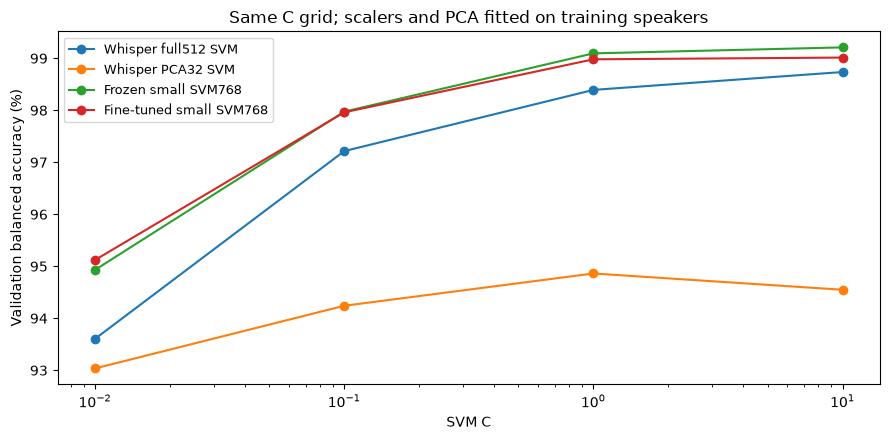

In [7]:
for name in NEW_MODELS:
    for c in C_VALUES:
        key = f'{name}|C={c:g}'
        if key in state['trials']:
            print('Reuse completed trial:', key)
            continue
        print('Fit:', key, flush=True)
        started = perf_counter()
        model = make_model(name, c).fit(inputs[name][train], y[train])
        fit_seconds = perf_counter()-started
        check_fit_scope(model, name, inputs[name][train])
        started = perf_counter()
        pred = score_predictions(model, inputs[name][val], frame.iloc[val], name, 'validation')
        row = dict(model=name, C=c, fit_seconds=fit_seconds,
                   validation_predict_and_score_seconds=perf_counter()-started,
                   **fw.flat_metrics(pred), origin='new small encoder SVM')
        state['trials'][key] = dict(row=row, predictions=pred)
        save_checkpoint(state)
        print(f'Validation BA: {row["balanced_accuracy"]:.4%}; macro F1: {row["macro_f1"]:.4f}', flush=True)

new_trials = pd.DataFrame([value['row'] for value in state['trials'].values()])
selected_c = dict(e2_c)
validation_parts = [e2_predictions['validation']]
for name in NEW_MODELS:
    best = choose_trial(new_trials.loc[new_trials.model.eq(name)].to_dict('records'))
    selected_c[name] = best['C']
    validation_parts.append(state['trials'][f'{name}|C={best["C"]:g}']['predictions'])
validation_predictions = pd.concat(validation_parts, ignore_index=True)
validation_trials = pd.concat([new_trials, e2_trials.assign(origin='completed E2 control')], ignore_index=True)
validation_trials['selected'] = [c == selected_c[name]
                                 for name, c in zip(validation_trials.model, validation_trials.C)]
validation_trials.to_csv(OUT / 'validation_trials.csv', index=False)
state['selected_C'] = selected_c
save_checkpoint(state)
display(validation_trials[['model', 'C', 'balanced_accuracy', 'macro_f1', 'selected', 'origin']])

fig, ax = plt.subplots(figsize=(9, 4.5))
for name in NAMES:
    part = validation_trials.loc[validation_trials.model.eq(name)].sort_values('C')
    ax.plot(part.C, 100*part.balanced_accuracy, 'o-', label=name)
ax.set(xscale='log', xlabel='SVM C', ylabel='Validation balanced accuracy (%)',
       title='Same C grid; scalers and PCA fitted on training speakers')
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()
plt.close(fig)

## 7. Refit fixed pipelines and score test data

C is now fixed. Refit scaling, optional PCA, and the SVM on development data. Score the same test clips as E2. The checkpoint stores fitted pipelines. Full768 models expect raw 768-value embeddings. Optional fusion models expect raw selected acoustic65 followed by raw Whisper768. The pipeline applies scaling and PCA.

In [8]:
for name in NEW_MODELS:
    if name in state['final']:
        print('Reuse completed development refit and test predictions:', name)
        continue
    print('Development refit:', name, flush=True)
    started = perf_counter()
    model = make_model(name, selected_c[name]).fit(inputs[name][dev], y[dev])
    fit_seconds = perf_counter()-started
    check_fit_scope(model, name, inputs[name][dev])
    started = perf_counter()
    pred = score_predictions(model, inputs[name][test], frame.iloc[test], name, 'test')
    state['final'][name] = dict(model=model, predictions=pred,
        timing=dict(model=name, final_fit_seconds=fit_seconds,
                    test_predict_and_score_seconds=perf_counter()-started,
                    origin='current run; cached input features'))
    save_checkpoint(state)

test_predictions = pd.concat([e2_predictions['test']]+
                              [state['final'][name]['predictions'] for name in NEW_MODELS], ignore_index=True)
for name in NAMES:
    check_predictions(test_predictions.loc[test_predictions.model.eq(name)], frame.iloc[test], name, 'test')
    check_predictions(validation_predictions.loc[validation_predictions.model.eq(name)], frame.iloc[val], name, 'validation')
all_predictions = pd.concat([validation_predictions, test_predictions], ignore_index=True)
assert len(all_predictions) == len(NAMES)*(len(val)+len(test))
all_predictions.to_csv(OUT / 'predictions.csv', index=False)
timing = pd.concat([
    pd.DataFrame([state['final'][name]['timing'] for name in NEW_MODELS]),
    pd.read_csv(E2 / 'timing.csv').assign(origin='completed E2 run; cached input features'),
], ignore_index=True)
display(timing)
print('Times include fitting and test predict + decision score calls. They exclude feature extraction.')
print('E2 and current-run times were measured in separate runs. They are descriptive, not an end-to-end benchmark.')

Development refit: Frozen small SVM768
Development refit: Fine-tuned small SVM768


,model,final_fit_seconds,test_predict_and_score_seconds,origin
0,Frozen small SVM768,60.123914,27.959960,current run; cached input features
1,Fine-tuned small SVM768,65.692190,29.707041,current run; cached input features
2,Whisper full512 SVM,50.497807,27.010955,completed E2 run; cached input features
3,Whisper PCA32 SVM,11.326246,2.914208,completed E2 run; cached input features


Times include fitting and test predict + decision score calls. They exclude feature extraction.
E2 and current-run times were measured in separate runs. They are descriptive, not an end-to-end benchmark.


## 8. Compare fixed models with paired speaker intervals

Balanced accuracy = (Singapore recall + non-Singapore specificity) / 2. Macro F1 gives equal weight to each class. ROC AUC uses the SVM decision score. FP = non-Singapore predicted as Singapore. FN = Singapore predicted as non-Singapore.

Sample whole speakers within each class. Use the same sample for every model. Keep all clips for each sampled speaker. Scores remain clip-based. The intervals condition on the fitted models; they exclude training and selection uncertainty. Secondary comparisons are descriptive, with no multiple-comparison correction. An interval that includes zero does not establish a gain or equivalence.

,model,C,balanced_accuracy,ba_ci95_low,ba_ci95_high,macro_f1,roc_auc,false_positive,false_negative,errors
0,Whisper full512 SVM,10.0,0.987268,0.982524,0.991576,0.987252,0.999089,45,33,78
1,Whisper PCA32 SVM,1.0,0.954260,0.943014,0.964188,0.954239,0.989560,148,132,280
2,Frozen small SVM768,10.0,0.993443,0.989588,0.996319,0.993462,0.999811,13,27,40
3,Fine-tuned small SVM768,10.0,0.993951,0.991072,0.996289,0.993953,0.999763,18,19,37


,candidate,reference,metric,difference_pp,low_pp,high_pp,candidate_only_correct,reference_only_correct
0,Fine-tuned small SVM768,Frozen small SVM768,balanced_accuracy,0.050802,-0.147730,0.262423,17,14
1,Fine-tuned small SVM768,Frozen small SVM768,macro_f1,0.049058,-0.148778,0.260918,17,14
2,Fine-tuned small SVM768,Whisper full512 SVM,balanced_accuracy,0.668320,0.350465,1.001566,59,18
3,Fine-tuned small SVM768,Whisper full512 SVM,macro_f1,0.670052,0.356168,1.005612,59,18


,model,source,label,clips,speakers,errors,metric,value
0,Whisper full512 SVM,common_voice,0,2913,1241,25,non-Singapore specificity,0.991418
1,Whisper full512 SVM,mnsc,1,3034,215,33,Singapore recall,0.989123
2,Whisper full512 SVM,speech_accent_archive,0,50,8,1,non-Singapore specificity,0.980000
3,Whisper full512 SVM,speechocean762,0,122,18,19,non-Singapore specificity,0.844262
4,Whisper PCA32 SVM,common_voice,0,2913,1241,96,non-Singapore specificity,0.967044
5,Whisper PCA32 SVM,mnsc,1,3034,215,132,Singapore recall,0.956493
6,Whisper PCA32 SVM,speech_accent_archive,0,50,8,3,non-Singapore specificity,0.940000
7,Whisper PCA32 SVM,speechocean762,0,122,18,49,non-Singapore specificity,0.598361
8,Frozen small SVM768,common_voice,0,2913,1241,8,non-Singapore specificity,0.997254
9,Frozen small SVM768,mnsc,1,3034,215,27,Singapore recall,0.991101


ASR exposure status: unresolved: exact 15k ASR exposure manifest not supplied
Fine-tuned small SVM768 minus Frozen small SVM768: +0.051 percentage points; 95% interval [-0.148, +0.262]. A gain is not established. This does not establish equivalence.
Fine-tuned small SVM768 minus Whisper full512 SVM: +0.668 percentage points; 95% interval [+0.350, +1.002]. The interval supports a gain on this retrospective test, subject to the ASR exposure audit.


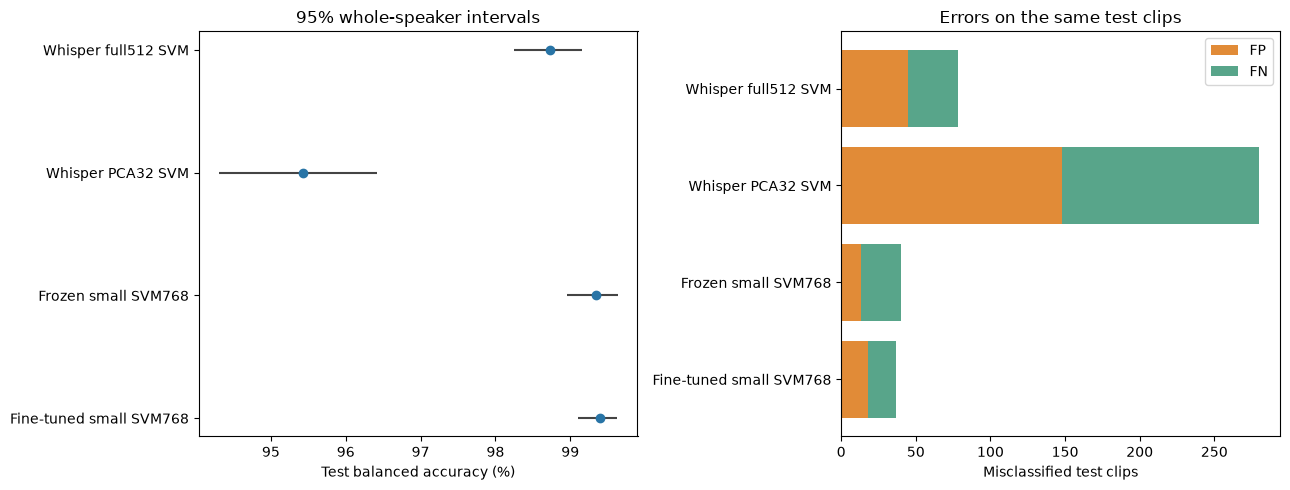

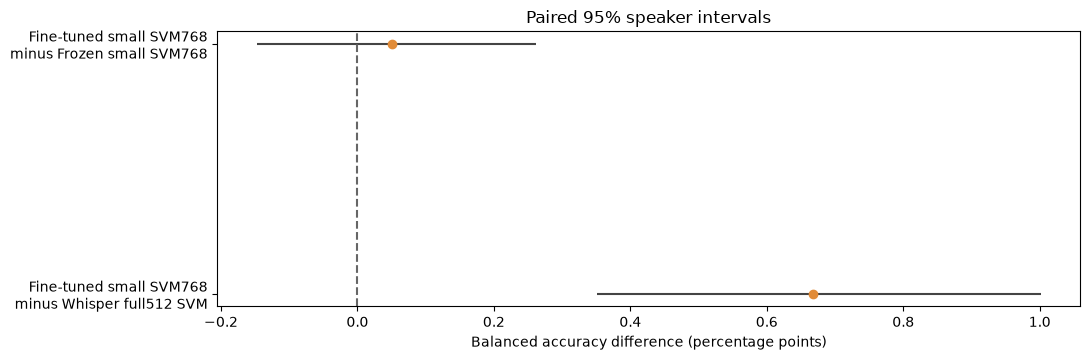

In [9]:
test_scores, score_details, paired = paired_bootstrap(test_predictions, NAMES)
test_scores['C'] = test_scores.model.map(selected_c)
test_scores.to_csv(OUT/'test_scores.csv', index=False)
subgroups = source_table(test_predictions)
display(test_scores[['model', 'C', 'balanced_accuracy', 'ba_ci95_low', 'ba_ci95_high',
                     'macro_f1', 'roc_auc', 'false_positive', 'false_negative', 'errors']])
paired_display = paired.assign(difference_pp=100*paired.difference,
                               low_pp=100*paired.ci95_low, high_pp=100*paired.ci95_high)
display(paired_display[['candidate', 'reference', 'metric', 'difference_pp', 'low_pp', 'high_pp',
                        'candidate_only_correct', 'reference_only_correct']])
display(subgroups)
print('ASR exposure status:', asr_audit['status'])
ba_pairs = paired.loc[paired.metric.eq('balanced_accuracy')].reset_index(drop=True)
for row in ba_pairs.itertuples(index=False):
    print(describe_difference(row))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(len(NAMES))
axes[0].hlines(x, 100*test_scores.ba_ci95_low, 100*test_scores.ba_ci95_high, color='#444444')
axes[0].scatter(100*test_scores.balanced_accuracy, x, color='#2874a6', zorder=3)
axes[0].set(yticks=x, yticklabels=NAMES, xlabel='Test balanced accuracy (%)', title='95% whole-speaker intervals')
axes[0].invert_yaxis()
axes[1].barh(x, test_scores.false_positive, label='FP', color='#e18b37')
axes[1].barh(x, test_scores.false_negative, left=test_scores.false_positive, label='FN', color='#58a58a')
axes[1].set(yticks=x, yticklabels=NAMES, xlabel='Misclassified test clips', title='Errors on the same test clips')
axes[1].invert_yaxis()
axes[1].legend()
fig.tight_layout()
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(11, 1.1*len(ba_pairs)+1.5))
x = np.arange(len(ba_pairs))
ax.hlines(x, 100*ba_pairs.ci95_low, 100*ba_pairs.ci95_high, color='#444444')
ax.scatter(100*ba_pairs.difference, x, color='#e18b37', zorder=3)
ax.axvline(0, color='#666666', linestyle='--')
ax.set(yticks=x, yticklabels=[f'{r.candidate}\nminus {r.reference}' for r in ba_pairs.itertuples()],
       xlabel='Balanced accuracy difference (percentage points)', title='Paired 95% speaker intervals')
ax.invert_yaxis()
fig.tight_layout()
plt.show()
plt.close(fig)

## 9. Save a short report

Keep two reusable feature arrays, one checkpoint, three CSV tables, one JSON record, and one Markdown report (eight files). Charts stay in this notebook. Save the executed notebook to retain them. No completed central archive is created before review.

The report records the ASR exposure limit, even when the score improves. If ASR training or model selection used classification validation/test speakers, do not claim an independent speaker-held-out gain. Locate the exact exposure records first. Review all speakers in conversations. A clean future test may require speakers excluded from all ASR exposure; that is a separate test with new frozen rules.

In [10]:
errors = test_predictions.loc[test_predictions.label.ne(test_predictions.prediction)].copy()
errors['absolute_margin'] = errors.decision_score.abs()
examples = errors.sort_values('absolute_margin', ascending=False).groupby('model', sort=False).head(5)
display(examples[['model', 'clip_id', 'speaker_group', 'source', 'label', 'prediction', 'decision_score']])
conclusions = [describe_difference(row) for row in ba_pairs.itertuples(index=False)]
lines = [
    '# E4.02.2: fine-tuned transcription encoder + SVM', '',
    'Status: numerical comparison complete. Retrospective test; ASR exposure audit requires review.', '',
    'Primary: fine-tuned small SVM768 minus frozen pretrained small SVM768. Secondary: comparison with completed frozen base.en SVM512. Only the matched small comparison controls encoder architecture and width.', '',
    'Use the exact final 24 October 40k prepared audio and speaker splits. Fit pipelines on training data; select C=0.01/0.1/1/10 by validation balanced accuracy, then macro F1, then smaller C. Refit on development. Test does not select C. Encoders are fixed during extraction. No transcript decoding or new encoder training.', '',
    '## ASR exposure audit', '', asr_audit['status'], '',
    'Do not interpret a numerical gain as an independent speaker-held-out gain until the exact 15k training and checkpoint-selection exposure, all conversation speakers, and cross-part ID mappings are checked. Different MNSC parts alone do not establish independence.', '',
    '```json', json.dumps(asr_audit, indent=2), '```', '',
    '## Test scores', '', markdown_table(test_scores), '',
    '## Paired differences', '', markdown_table(paired_display), '', *conclusions, '',
    'Primary interval: 2,000 whole-speaker paired bootstrap samples, stratified by class. Intervals condition on fixed models and exclude training/selection uncertainty. Secondary comparisons are descriptive; no multiple-comparison correction.', '',
    '## Source scores', '', markdown_table(subgroups), '',
    'All positive clips are MNSC; source and class are confounded. These results do not isolate accent cues from corpus cues.', '',
    '## Time', '', markdown_table(timing), '',
    'Classifier times use cached features and include separate predict and decision-score calls. E2 times were measured in a separate run. Extraction times below include model loading and file I/O. These are descriptive, not a deployment benchmark.', '',
    '```json', json.dumps(state['extraction'], indent=2), '```', '',
    '## Error examples', '', 'Highest absolute SVM margins among errors; margins are not probabilities.', '',
    markdown_table(examples[['model', 'clip_id', 'source', 'label', 'prediction', 'decision_score']]), '',
    '## Files', '',
    'Two *_features.npy files hold raw encoder embeddings in audited dataset order. study.joblib holds extraction progress, C trials, and fitted pipelines. validation_trials.csv holds all C candidates. predictions.csv holds selected validation and fixed test predictions. test_scores.csv holds scores and intervals. run_record.json holds provenance and paired differences. report.md is this report. Save this notebook for charts.', '',
]
(OUT/'report.md').write_text('\n'.join(lines))
record.update(status='complete', completed_utc=datetime.now(timezone.utc).isoformat(),
              interpretation_status='ASR exposure provenance requires manual review',
              selected_C=selected_c, extraction=state['extraction'], test_metrics=score_details,
              paired_differences=paired.to_dict('records'), source_scores=subgroups.to_dict('records'),
              timing=timing.to_dict('records'), test_clips=len(test),
              test_speakers=frame.iloc[test].speaker_group.nunique())
record['generated_files'] = {p.name: sha256(p) for p in OUT.iterdir() if p.name != 'run_record.json'}
fw.write_json(OUT/'run_record.json', record)
display(Markdown('**Comparison complete.** Save this notebook. Report: `'+str(OUT/'report.md')+'`'))

,model,clip_id,speaker_group,source,label,prediction,decision_score
12158,Whisper PCA32 SVM,speechocean762::so762_012930040,speechocean762::so762_1293,speechocean762,0,1,3.264584
12168,Whisper PCA32 SVM,speechocean762::so762_013720189,speechocean762::so762_1372,speechocean762,0,1,3.239443
9512,Whisper PCA32 SVM,mnsc::mnsc_part1-train_00002_01341,mnsc::mnsc_07000000,mnsc,1,0,-3.160819
9993,Whisper PCA32 SVM,mnsc::mnsc_part1-train_00194_00628,mnsc::mnsc_07000000,mnsc,1,0,-2.632422
12162,Whisper PCA32 SVM,speechocean762::so762_012930225,speechocean762::so762_1293,speechocean762,0,1,2.489282
6077,Whisper full512 SVM,speechocean762::so762_021290282,speechocean762::so762_2129,speechocean762,0,1,1.111493
6006,Whisper full512 SVM,speechocean762::so762_004610230,speechocean762::so762_0461,speechocean762,0,1,1.089029
3359,Whisper full512 SVM,mnsc::mnsc_part1-train_00002_00802,mnsc::mnsc_07000000,mnsc,1,0,-1.036103
6041,Whisper full512 SVM,speechocean762::so762_012930114,speechocean762::so762_1293,speechocean762,0,1,1.015300
22231,Fine-tuned small SVM768,mnsc::mnsc_part1-train_00194_00628,mnsc::mnsc_07000000,mnsc,1,0,-0.991812


**Comparison complete.** Save this notebook. Report: `/home/mh/nusproj/singlish-whisper/outputs/e4_02_2_finetuned_whisper_svm_40000/report.md`